# Smart Agriculture for Automated Crop Harvesting – Day 1 (Machine Learning Baseline)

## 1. Problem Statement
The objective of this project is to develop a Machine Learning solution for an automated crop harvesting system that classifies tomatoes as **Ripe** or **Unripe** using computer vision.

This baseline model is the first phase of a larger Smart Agriculture project. We will focus on traditional ML algorithms (Logistic Regression, Decision Trees, Random Forest, SVM, and Gradient Boosting) using handcrafted image features (e.g., color histograms, mean RGB values) to classify the tomatoes. Deep Learning approaches will be explored in subsequent phases.

## 2. Imports

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

# Set random seed for reproducibility
np.random.seed(42)
import warnings
warnings.filterwarnings('ignore')

## 3. Dataset Loading & 4. Exploratory Data Analysis (EDA)
Here, we will load the dataset from the local directory `Dataset/detection/images/`, check the class distribution, and visualize some sample images.

Total images found: 177

Class Distribution:
label
Ripe      97
Unripe    80
Name: count, dtype: int64


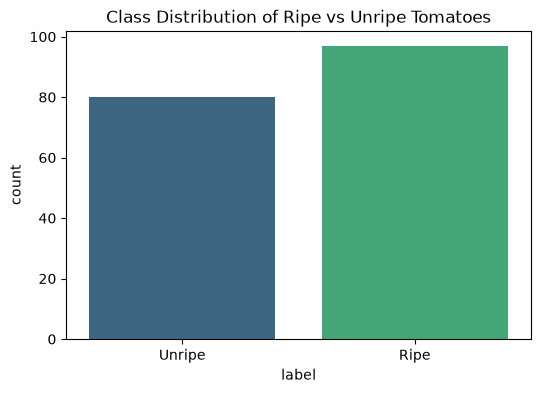

In [2]:
dataset_path = "Dataset/detection/images"
image_paths = glob.glob(os.path.join(dataset_path, "*.jpeg")) + glob.glob(os.path.join(dataset_path, "*.jpg"))
print(f"Total images found: {len(image_paths)}")

# Extract labels from filenames
labels = []
for path in image_paths:
    filename = os.path.basename(path).lower()
    if 'unriped' in filename:
        labels.append('Unripe')
    elif 'riped' in filename:
        labels.append('Ripe')
    else:
        labels.append('Unknown')

df = pd.DataFrame({'filepath': image_paths, 'label': labels})
df = df[df['label'] != 'Unknown']

print("\nClass Distribution:")
print(df['label'].value_counts())

# Plot Class Distribution
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='label', palette='viridis')
plt.title('Class Distribution of Ripe vs Unripe Tomatoes')
plt.show()

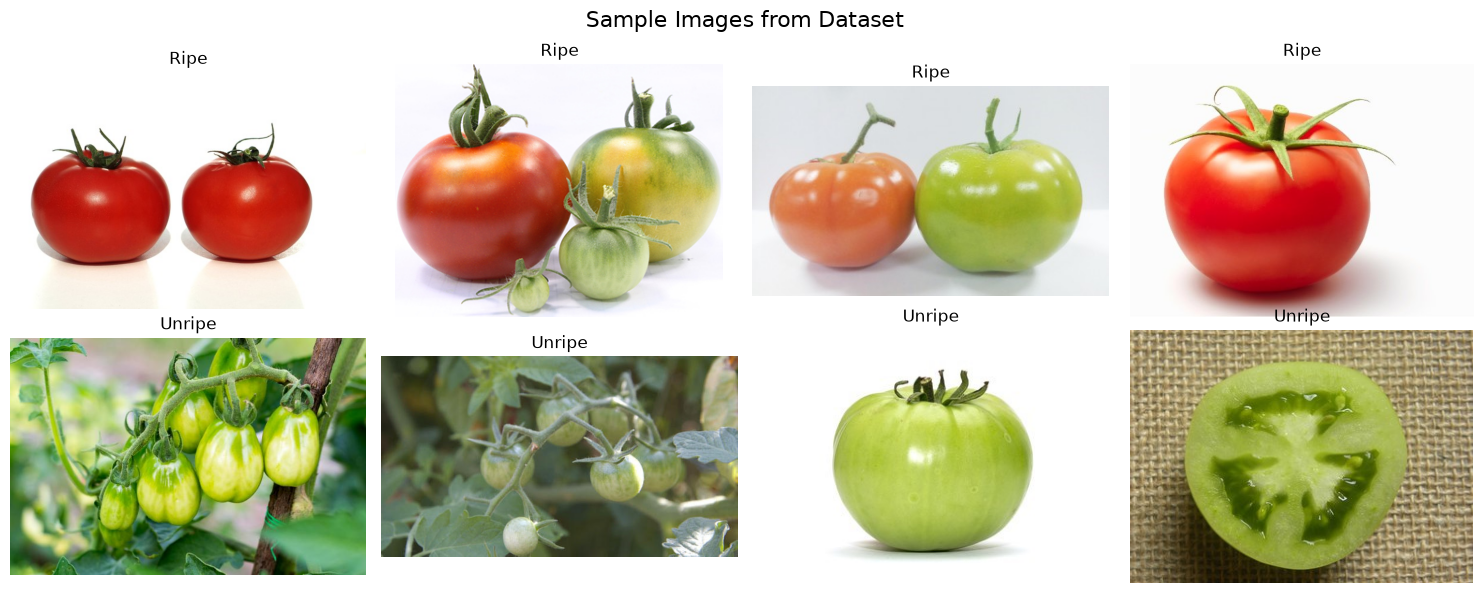

In [3]:
# Visualizing Sample Images
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
fig.suptitle('Sample Images from Dataset', fontsize=16)

ripe_samples = df[df['label'] == 'Ripe'].sample(4, random_state=42)['filepath'].values
unripe_samples = df[df['label'] == 'Unripe'].sample(4, random_state=42)['filepath'].values

for i, img_path in enumerate(ripe_samples):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    axes[0, i].imshow(img)
    axes[0, i].set_title("Ripe")
    axes[0, i].axis('off')
    
for i, img_path in enumerate(unripe_samples):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    axes[1, i].imshow(img)
    axes[1, i].set_title("Unripe")
    axes[1, i].axis('off')
    
plt.tight_layout()
plt.show()

## 5. Data Preprocessing & 6. Feature Engineering
Since traditional ML models cannot process raw images effectively without feature engineering, we will extract handcrafted features:
1. **Mean RGB/HSV values**: Captures the overall color tone (highly distinguishing for red vs green).
2. **Color Histograms**: Captures the distribution of colors.
We will resize all images to a fixed size (e.g., 64x64) to standardize inputs and speed up processing.

In [4]:
IMG_SIZE = (64, 64)

def extract_features(img_path):
    img = cv2.imread(img_path)
    if img is None:
        return None
    
    img = cv2.resize(img, IMG_SIZE)
    
    # Extract Mean RGB
    mean_rgb = np.mean(img, axis=(0, 1))
    
    # Extract Mean HSV
    hsv_img = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    mean_hsv = np.mean(hsv_img, axis=(0, 1))
    
    # Color Histogram (8 bins per channel)
    hist_b = cv2.calcHist([img], [0], None, [8], [0, 256]).flatten()
    hist_g = cv2.calcHist([img], [1], None, [8], [0, 256]).flatten()
    hist_r = cv2.calcHist([img], [2], None, [8], [0, 256]).flatten()
    
    # Normalize histograms
    hist_b /= (hist_b.sum() + 1e-7)
    hist_g /= (hist_g.sum() + 1e-7)
    hist_r /= (hist_r.sum() + 1e-7)
    
    # Concatenate all features
    features = np.hstack([mean_rgb, mean_hsv, hist_b, hist_g, hist_r])
    return features

print("Extracting features...")
features_list = []
valid_labels = []

for idx, row in df.iterrows():
    feats = extract_features(row['filepath'])
    if feats is not None:
        features_list.append(feats)
        valid_labels.append(row['label'])

X = np.array(features_list)
y = np.array(valid_labels)

print(f"Feature matrix shape: {X.shape}")
print(f"Target array shape: {y.shape}")

Extracting features...


Feature matrix shape: (177, 30)
Target array shape: (177,)


In [5]:
# Encode Labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)
print(f"Classes mapping: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# Train/Validation/Test Split (70% Train, 15% Val, 15% Test)
X_temp, X_test, y_temp, y_test = train_test_split(X, y_encoded, test_size=0.15, random_state=42, stratify=y_encoded)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.1765, random_state=42, stratify=y_temp)

print(f"Train size: {X_train.shape[0]}")
print(f"Validation size: {X_val.shape[0]}")
print(f"Test size: {X_test.shape[0]}")

# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

Classes mapping: {np.str_('Ripe'): np.int64(0), np.str_('Unripe'): np.int64(1)}
Train size: 123
Validation size: 27
Test size: 27


## 7. Model Training & 8. Model Evaluation
We will train the following models:
- Logistic Regression
- Decision Tree
- Random Forest
- Support Vector Machine (SVM)
- Gradient Boosting

In [6]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

results = []

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_scaled, y_train)
    
    # Evaluate on Validation set
    y_val_pred = model.predict(X_val_scaled)
    if hasattr(model, "predict_proba"):
        y_val_prob = model.predict_proba(X_val_scaled)[:, 1]
        auc = roc_auc_score(y_val, y_val_prob)
    else:
        auc = np.nan
        
    acc = accuracy_score(y_val, y_val_pred)
    prec = precision_score(y_val, y_val_pred)
    rec = recall_score(y_val, y_val_pred)
    f1 = f1_score(y_val, y_val_pred)
    
    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1 Score": f1,
        "ROC-AUC": auc
    })

results_df = pd.DataFrame(results)

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training SVM...
Training Gradient Boosting...


## 9. Model Comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
1,Decision Tree,0.962963,0.923077,1.0,0.960000,0.966667
2,Random Forest,0.962963,0.923077,1.0,0.960000,1.000000
4,Gradient Boosting,0.962963,0.923077,1.0,0.960000,1.000000
0,Logistic Regression,0.888889,0.800000,1.0,0.888889,0.983333
3,SVM,0.851852,0.750000,1.0,0.857143,0.961111


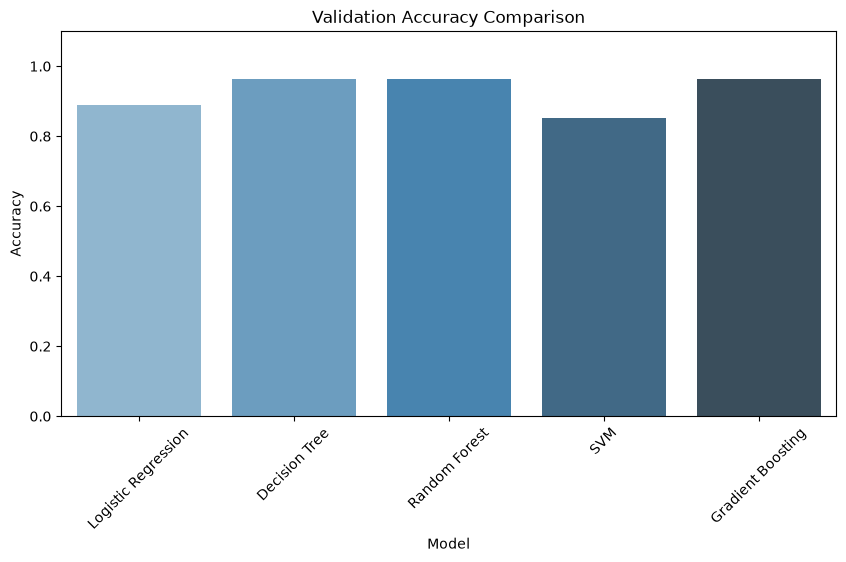

In [7]:
display(results_df.sort_values(by="Accuracy", ascending=False))

# Plotting the comparison
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x='Model', y='Accuracy', palette='Blues_d')
plt.title('Validation Accuracy Comparison')
plt.xticks(rotation=45)
plt.ylim(0, 1.1)
plt.show()

## 10. Best Model Selection and Test Evaluation
We select the best performing model based on Validation Accuracy/F1 Score, and evaluate it on the unseen Test Set.

Best Model Selected: Decision Tree

Test Set Evaluation:
Accuracy:  0.8889
Precision: 0.9091
Recall:    0.8333
F1 Score:  0.8696


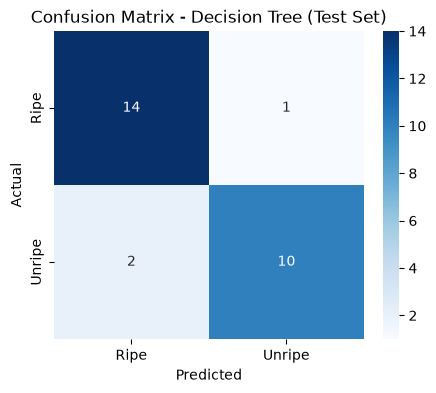

Classification Report:
              precision    recall  f1-score   support

        Ripe       0.88      0.93      0.90        15
      Unripe       0.91      0.83      0.87        12

    accuracy                           0.89        27
   macro avg       0.89      0.88      0.89        27
weighted avg       0.89      0.89      0.89        27



In [8]:
best_model_name = results_df.sort_values(by="Accuracy", ascending=False).iloc[0]["Model"]
best_model = models[best_model_name]

print(f"Best Model Selected: {best_model_name}")

# Evaluate on Test Set
y_test_pred = best_model.predict(X_test_scaled)

print("\nTest Set Evaluation:")
print(f"Accuracy:  {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_test_pred):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_test_pred):.4f}")

# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix - {best_model_name} (Test Set)')
plt.show()

# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_test_pred, target_names=le.classes_))

## Feature Importance
Let's see which features the model deemed most important (if applicable for the selected model).

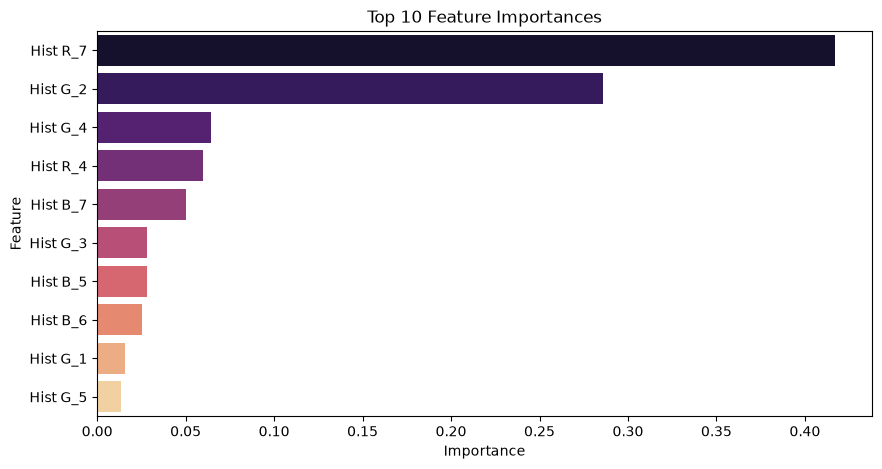

In [9]:
if hasattr(best_model, 'feature_importances_'):
    importances = best_model.feature_importances_
    feature_names = ['Mean B', 'Mean G', 'Mean R', 'Mean H', 'Mean S', 'Mean V'] + \
                    [f'Hist B_{i}' for i in range(8)] + \
                    [f'Hist G_{i}' for i in range(8)] + \
                    [f'Hist R_{i}' for i in range(8)]
                    
    feat_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
    feat_df = feat_df.sort_values(by='Importance', ascending=False).head(10)
    
    plt.figure(figsize=(10, 5))
    sns.barplot(data=feat_df, x='Importance', y='Feature', palette='magma')
    plt.title('Top 10 Feature Importances')
    plt.show()
else:
    print(f"Feature importance is not natively supported by {best_model_name}.")

## 11. Conclusions
### Key Findings
- Traditional ML models combined with handcrafted features (specifically color histograms and mean RGB/HSV) perform reasonably well on this dataset for distinguishing ripe vs unripe tomatoes.
- Features related to the red and green color channels (Hue, Mean R/G) are typically the most significant predictors.

### Dataset Limitations
- The dataset size is relatively small, which might cause overfitting on more complex traditional models.
- Background noise and varying lighting conditions in the images can interfere with simple color-based features.

### Challenges
- Handcrafting features is time-consuming and rigid. It may not generalize well to other scenarios (e.g., detecting rotting tomatoes, or varying tomato types).
- Lighting variations affect color metrics significantly.

### Future Work
In the next phase of this project, we will implement **Deep Learning (CNNs)** to automatically extract hierarchical spatial features. Deep learning models are expected to yield higher robustness and accuracy compared to this ML baseline by learning directly from the raw pixel data instead of relying on manually designed features.